In [2]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import datetime 
import utils

In [3]:

GTFS_zip_files=['GTFS_2025-08-13T04-20-01.zip', 'GTFS_2025-08-22T04-20-01.zip',
                'GTFS_2025-09-03T04-20-01.zip','GTFS_2025-09-04T04-20-01.zip','GTFS_2025-09-15T04-20-01.zip']
GTFS_dates=['2025-08-13','2025-08-22','2025-09-03','2025-09-04','2025-09-15']
data_dir="data"

In [2]:
results=pd.DataFrame(columns=['date', 'routes_id_stop_times','routes_id_both','routes_id_routes',
                              'stops_stops','stops_both','stops_positions',
                              'ligne-direction-arrêt_GTFS','ligne-direction-arrêt_positions',
                              's'])

for active_GTFS_zip_file in GTFS_zip_files:
    geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file,data_dir)
    display(geo_stops.query('stop_name=="CHURCHILL"').explore())

Feed infos: GTFS_2025-08-13T04-20-01.zip
Version: 2_18_20250804_010621
From 2025-08-04 00:00:00 to 2025-08-31 00:00:00
Files readlendar_dates


Feed infos: GTFS_2025-08-22T04-20-01.zip
Version: 2_19_20250818_010705
From 2025-08-18 00:00:00 to 2025-09-14 00:00:00
Files readlendar_dates


Feed infos: GTFS_2025-09-03T04-20-01.zip
Version: 2_20_20250902_105301
From 2025-09-01 00:00:00 to 2025-09-28 00:00:00
Files readlendar_dates


Feed infos: GTFS_2025-09-04T04-20-01.zip
Version: 2_20_20250903_010546
From 2025-09-01 00:00:00 to 2025-09-28 00:00:00
Files readlendar_dates


Feed infos: GTFS_2025-09-15T04-20-01.zip
Version: 2_21_20250915_010631
From 2025-09-15 00:00:00 to 2025-10-12 00:00:00
Files readlendar_dates


# Évolution du nombre de ligne en fonction du temps

In [8]:
active_stop_times.columns

Index(['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence',
       'pickup_type', 'drop_off_type', 'source', 'arrival_datetime',
       'departure_datetime'],
      dtype='object')

In [9]:
print(active_stop_times[['stop_sequence','arrival_datetime','departure_datetime']].min())
print(active_stop_times[['stop_sequence','arrival_datetime','departure_datetime']].max())

stop_sequence                                 1
arrival_datetime      2025-08-21 04:26:00+02:00
departure_datetime    2025-08-21 04:26:00+02:00
dtype: object
stop_sequence                                37
arrival_datetime      2025-08-22 01:37:00+02:00
departure_datetime    2025-08-22 01:37:00+02:00
dtype: object


In [20]:
sdate_debut="2025-08-15"#"2025-09-01"#
sdate_fin="2025-09-15"
date_fin=pd.Timestamp(sdate_fin, tz='UTC+02:00')#pd.to_datetime(sdate_fin)
date=pd.Timestamp(sdate_debut, tz='UTC+02:00')

GTFS_i=0
while(sdate_debut>=GTFS_dates[GTFS_i+1]):
        GTFS_i=GTFS_i+1

active_GTFS_zip_file=GTFS_zip_files[GTFS_i]
geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file,data_dir)
dfs=[]
uniques=[]
uniques_per_day=[]
while date<=date_fin:
    sdate=str(date.date())
    print("-------------------"+sdate+"-------------------")
    if(sdate>=GTFS_dates[GTFS_i+1]):
        GTFS_i=GTFS_i+1
        active_GTFS_zip_file=GTFS_zip_files[GTFS_i]
        geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file,data_dir)
    active_stop_times, active_trips =utils.get_active_stop_times(sdate, trips, stop_times, calendar, calendar_dates)
    #%% Convert the time columns of active_stop_times to datetime
    active_stop_times=active_stop_times.assign(arrival_datetime=date+pd.to_timedelta(active_stop_times['arrival_time']),
                                               departure_datetime=date+pd.to_timedelta(active_stop_times['departure_time']))
    
#    active_stop_times=active_stop_times.sort_values('arrival_datetime')
#    counts=active_stop_times.groupby('arrival_datetime', as_index=False).count()
#    unique=active_stop_times.groupby('arrival_datetime', as_index=False).nunique()
#    active_stop_times['date']=active_stop_times['arrival_datetime'].dt.date
#    unique_per_day=active_stop_times.groupby('date', as_index=False).nunique()
#    dfs.append(counts)
#    uniques.append(unique)
#    uniques_per_day.append(unique_per_day)
    print(date)
    print(active_stop_times['arrival_datetime'].min())
    print(active_stop_times['arrival_datetime'].max())
    
    date=date+pd.Timedelta(value=1, unit='day')
all_counts=pd.concat(dfs)
all_uniques=pd.concat(uniques)
all_uniques_day=pd.concat(uniques_per_day)
all_uniques=all_uniques.reset_index(drop=True)
all_counts=all_counts.reset_index(drop=True)

Feed infos: GTFS_2025-08-13T04-20-01.zip
Version: 2_18_20250804_010621
From 2025-08-04 00:00:00 to 2025-08-31 00:00:00
Files read              
-------------------2025-08-15-------------------


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


2025-08-15 00:00:00+02:00
2025-08-15 04:26:00+02:00
2025-08-16 03:58:00+02:00
-------------------2025-08-16-------------------


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


2025-08-16 00:00:00+02:00
2025-08-16 04:26:00+02:00
2025-08-17 03:58:00+02:00
-------------------2025-08-17-------------------


...

C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


2025-09-14 00:00:00+02:00
2025-09-14 04:26:00+02:00
2025-09-15 01:41:00+02:00
-------------------2025-09-15-------------------
Feed infos: GTFS_2025-09-15T04-20-01.zip
Version: 2_21_20250915_010631
From 2025-09-15 00:00:00 to 2025-10-12 00:00:00
Files read              


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


2025-09-15 00:00:00+02:00
2025-09-15 04:26:00+02:00
2025-09-16 01:41:00+02:00


ValueError: No objects to concatenate

In [11]:
all_counts

,arrival_datetime,trip_id,arrival_time,departure_time,stop_id,stop_sequence,pickup_type,drop_off_type,source,departure_datetime
0,2025-08-15 04:26:00+02:00,2,2,2,2,2,2,2,2,2
1,2025-08-15 04:27:14+02:00,1,1,1,1,1,1,1,1,1
2,2025-08-15 04:28:14+02:00,1,1,1,1,1,1,1,1,1
3,2025-08-15 04:29:00+02:00,2,2,2,2,2,2,2,2,2
4,2025-08-15 04:29:20+02:00,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...
67393,2025-09-16 01:36:04+02:00,1,1,1,1,1,1,1,1,1
67394,2025-09-16 01:37:00+02:00,1,1,1,1,1,1,1,1,1
67395,2025-09-16 01:37:57+02:00,1,1,1,1,1,1,1,1,1
67396,2025-09-16 01:39:00+02:00,1,1,1,1,1,1,1,1,1


In [ ]:
all_uniques

In [12]:
all_uniques_day

,date,trip_id,arrival_time,departure_time,stop_id,stop_sequence,pickup_type,drop_off_type,source,arrival_datetime,departure_datetime
0,2025-08-15,11381,59161,59129,2252,37,2,2,1,59161,59129
1,2025-08-16,780,4714,4704,2163,37,2,2,1,4714,4704
0,2025-08-16,11889,59867,59792,2271,37,2,2,1,59867,59792
1,2025-08-17,778,4699,4696,2161,37,2,2,1,4699,4696
0,2025-08-17,11350,59231,59189,2255,37,2,2,1,59231,59189
...,...,...,...,...,...,...,...,...,...,...,...
1,2025-09-14,753,4668,4687,2187,37,2,2,1,4668,4687
0,2025-09-14,11230,58978,59105,2288,37,2,2,1,58978,59105
1,2025-09-15,619,2776,2792,2070,37,2,2,1,2776,2792
0,2025-09-15,18929,64611,64555,2324,37,2,2,1,64611,64555


<Axes: xlabel='arrival_datetime'>

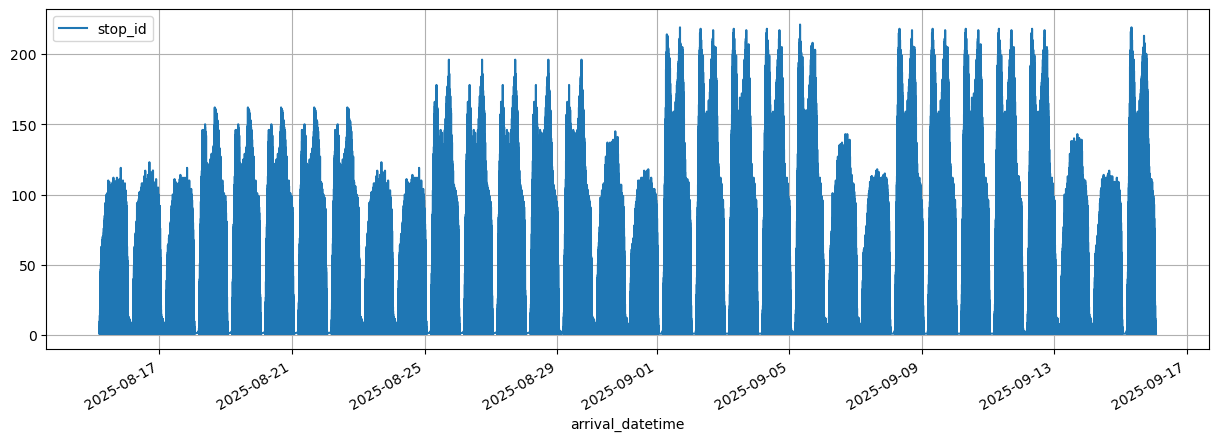

In [18]:
all_counts.plot(x='arrival_datetime',figsize=(15, 5), y='stop_id', grid=True)

<Axes: xlabel='arrival_datetime'>

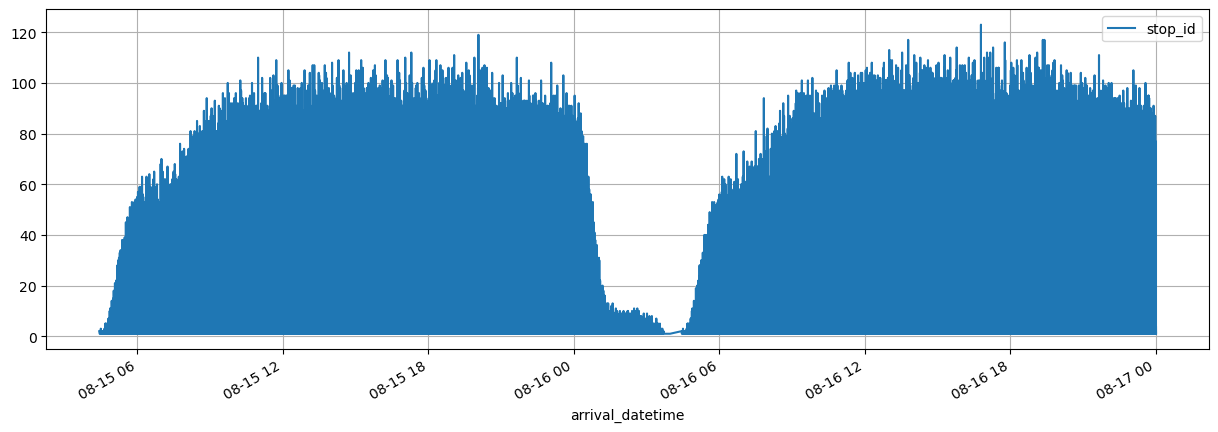

In [19]:
d=pd.Timestamp("2025-08-17", tz='UTC+02:00')
all_counts.query("arrival_datetime<@d").plot(x='arrival_datetime',figsize=(15, 5), y='stop_id', grid=True)

<Axes: title={'center': 'Number of rows per day'}, xlabel='arrival_datetime'>

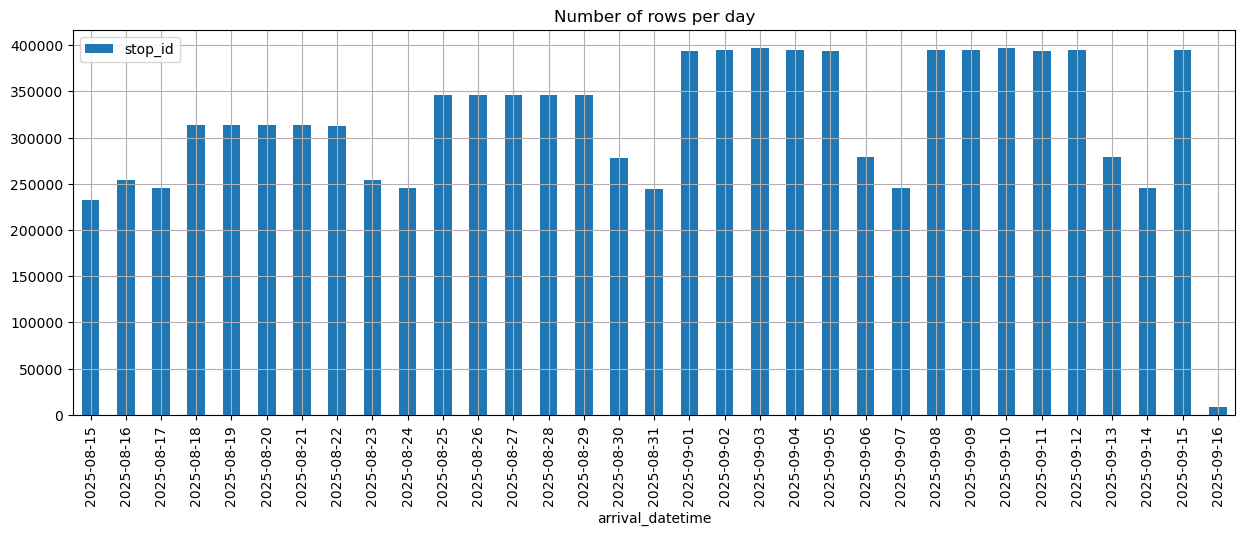

In [17]:
all_counts.groupby(all_counts["arrival_datetime"].dt.date).agg({'stop_id':'sum'}).plot.bar(figsize=(15, 5), y='stop_id', title='Number of rows per day', grid=True)

<Axes: title={'center': 'Number of rows depending on the time of the day'}, xlabel='Hour'>

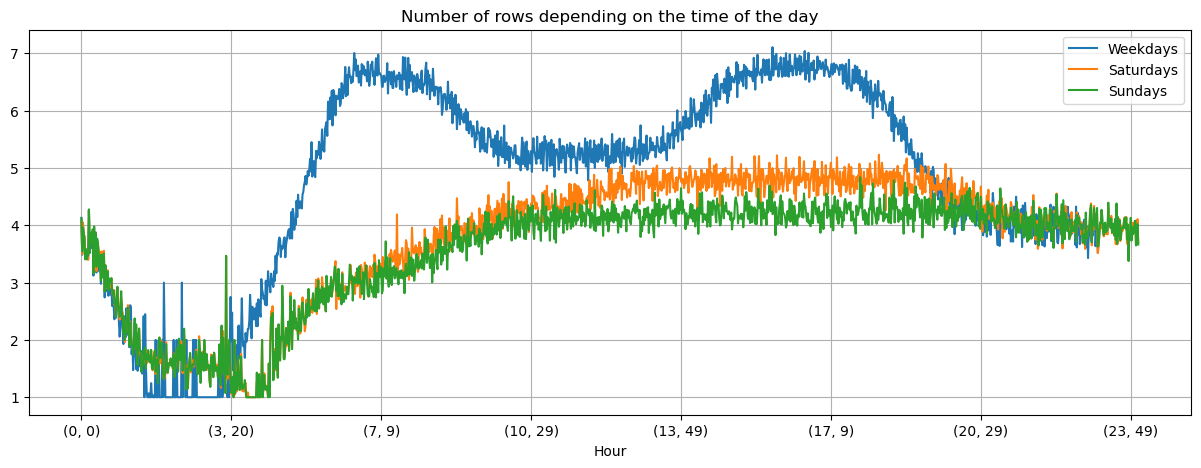

In [16]:
fig=all_counts[all_counts["arrival_datetime"].dt.weekday<5].groupby([all_counts["arrival_datetime"].dt.hour,all_counts["arrival_datetime"].dt.minute]).mean().plot(figsize=(15, 5), y='stop_id', label='Weekdays', grid=True, xlabel='Hour')
#Week-ends
fig=all_counts[all_counts["arrival_datetime"].dt.weekday==5].groupby([all_counts["arrival_datetime"].dt.hour,all_counts["arrival_datetime"].dt.minute]).mean().plot(figsize=(15, 5), y='stop_id', label='Saturdays', grid=True, xlabel='Hour', ax=fig)
all_counts[all_counts["arrival_datetime"].dt.weekday==6].groupby([all_counts["arrival_datetime"].dt.hour,all_counts["arrival_datetime"].dt.minute]).mean().plot(figsize=(15, 5), y='stop_id', label='Sundays', title='Number of rows depending on the time of the day', grid=True, xlabel='Hour',ax=fig)

# Lifespan of trips/vehicles

In [13]:
sdate_debut="2025-08-21"#"2025-09-01"#
sdate_fin="2025-09-15"
date_fin=pd.Timestamp(sdate_fin, tz='UTC+02:00')#pd.to_datetime(sdate_fin)
date=pd.Timestamp(sdate_debut, tz='UTC+02:00')

GTFS_i=0
while(sdate_debut>=GTFS_dates[GTFS_i+1]):
        GTFS_i=GTFS_i+1

active_GTFS_zip_file=GTFS_zip_files[GTFS_i]
geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file,data_dir)
dfs=[]
while date<=date_fin:
    sdate=str(date.date())
    print("-------------------"+sdate+"-------------------")
    if(sdate>=GTFS_dates[GTFS_i+1]):
        GTFS_i=GTFS_i+1
        active_GTFS_zip_file=GTFS_zip_files[GTFS_i]
        geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file,data_dir)
    active_stop_times, active_trips =utils.get_active_stop_times(sdate, trips, stop_times, calendar, calendar_dates)
    #%% Convert the time columns of active_stop_times to datetime
    active_stop_times=active_stop_times.assign(arrival_datetime=active_stop_times['arrival_time'].str.split(':').apply(lambda x:date+datetime.timedelta(hours=int(x[0]), minutes=int(x[1]), seconds=int(x[2]))),
                             departure_datetime=active_stop_times['departure_time'].str.split(':').apply(lambda x:date+datetime.timedelta(hours=int(x[0]), minutes=int(x[1]), seconds=int(x[2]))))

    
    tomorrow=date+datetime.timedelta(days=1)
    pre_24_trips=active_stop_times.query("arrival_datetime<@tomorrow")['trip_id'].unique()
    post_24_trips=active_stop_times.query("arrival_datetime>@tomorrow")['trip_id'].unique()
    tomorrow_trips=np.setdiff1d(post_24_trips,pre_24_trips, assume_unique=True)
    today_into_tomorrow_trips=np.intersect1d(post_24_trips,pre_24_trips, assume_unique=True)

    inter_days_GTFS=active_stop_times[active_stop_times['trip_id'].isin(today_into_tomorrow_trips)]
    
    dfs.append(inter_days_GTFS)
    print(date.date())
    print(f"Nombre de véhicule du jour circulant le lendemain:{len(today_into_tomorrow_trips)}")
    date=date+pd.Timedelta(value=1, unit='day')
all_inter_GTFS=pd.concat(dfs)

Feed infos: GTFS_2025-08-13T04-20-01.zip
Version: 2_18_20250804_010621
From 2025-08-04 00:00:00 to 2025-08-31 00:00:00
Files read              
-------------------2025-08-21-------------------


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


2025-08-21
Nombre de véhicule du jour circulant le lendemain:231
-------------------2025-08-22-------------------
Feed infos: GTFS_2025-08-22T04-20-01.zip
Version: 2_19_20250818_010705
From 2025-08-18 00:00:00 to 2025-09-14 00:00:00
Files read              


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


2025-08-22
Nombre de véhicule du jour circulant le lendemain:232
-------------------2025-08-23-------------------


...

2025-09-13
Nombre de véhicule du jour circulant le lendemain:234
-------------------2025-09-14-------------------


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


2025-09-14
Nombre de véhicule du jour circulant le lendemain:233
-------------------2025-09-15-------------------
Feed infos: GTFS_2025-09-15T04-20-01.zip
Version: 2_21_20250915_010631
From 2025-09-15 00:00:00 to 2025-10-12 00:00:00
Files read              


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


2025-09-15
Nombre de véhicule du jour circulant le lendemain:233


In [16]:
trip_groups=all_inter_GTFS.groupby('trip_id')['departure_datetime'].agg(['min','max', 'count'])
trip_groups=trip_groups.sort_values('min')
trip_groups

,min,max,count
trip_id,,,
127231736301617000,2025-08-21 23:18:00+02:00,2025-08-23 00:03:00+02:00,58
127231737301617000,2025-08-21 23:19:00+02:00,2025-08-23 00:03:00+02:00,58
126596557298238000,2025-08-21 23:19:00+02:00,2025-08-23 00:02:00+02:00,62
127231626301616000,2025-08-21 23:23:00+02:00,2025-08-23 00:12:00+02:00,66
127435736301118001,2025-08-21 23:24:00+02:00,2025-08-23 00:04:00+02:00,64
...,...,...,...
127703324304961000,2025-09-15 23:58:00+02:00,2025-09-16 00:24:00+02:00,19
128523984309262003,2025-09-15 23:59:00+02:00,2025-09-16 00:15:00+02:00,12
128396265308455001,2025-09-15 23:59:00+02:00,2025-09-16 00:16:00+02:00,13


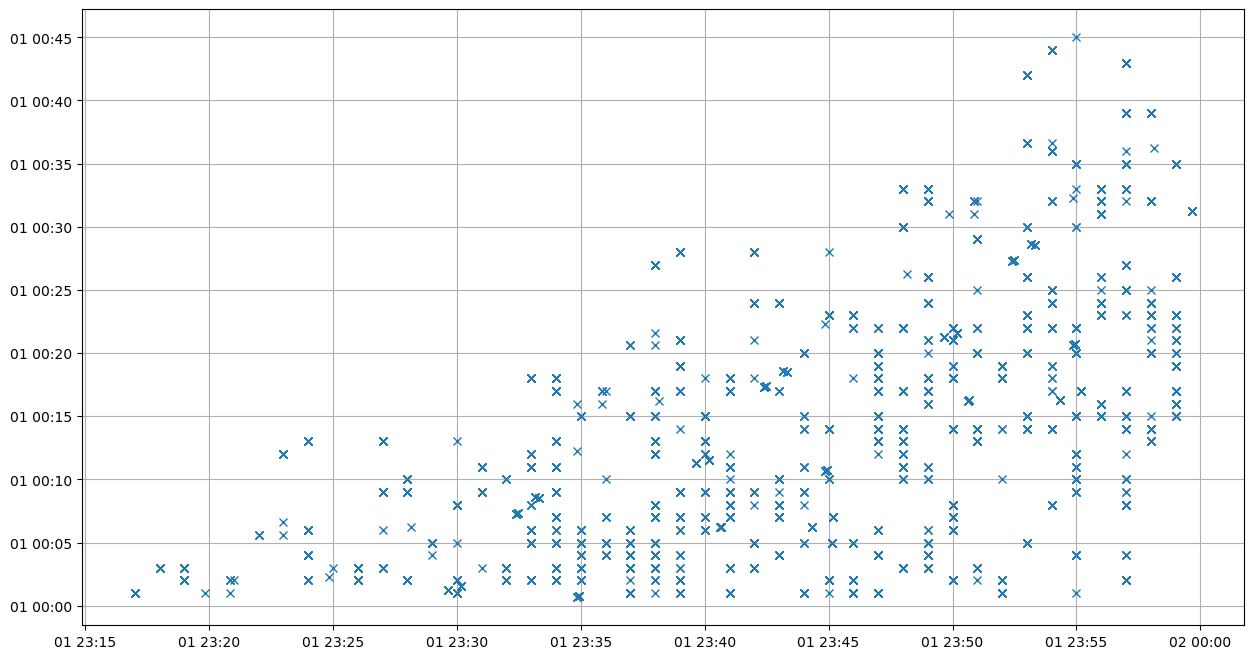

In [17]:
plt.figure(figsize=(15, 8))
plt.plot(trip_groups['min'].apply(lambda x:x.replace(month=1, day=1)),
         trip_groups['max'].apply(lambda x:x.replace(month=1, day=1)),
         
        'x')
plt.grid()